# Lab Assignment 8 – UCS420 Cognitive Computing
**Topic:** NLP using Python-II (Feature extraction from text, sentiment analysis and text generation)

**Name:** Arnav Gupta  
**Roll No.:** 1024170057  
**Group:** 3Q25

In [1]:
# Setup: import libraries and download the NLTK data we need (run once)
import re
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

True

## Q1. Text preprocessing
I chose **technology and gadgets** as my favourite topic.

In [2]:
paragraph = (
    "Technology is something I use every single day, and gadgets are my biggest interest. "
    "My laptop is my favourite device because I use it for coding, assignments and watching tutorials. "
    "I always follow the launch of new smartphones, smartwatches and earbuds with a lot of excitement! "
    "For me a good gadget is not only about specs, it is about the design, battery backup and how easy it is to use. "
    "Last semester my friends and I made a small line following robot in the college lab using an Arduino. "
    "I feel technology saves time, solves problems and makes learning more fun."
)
print(paragraph)

Technology is something I use every single day, and gadgets are my biggest interest. My laptop is my favourite device because I use it for coding, assignments and watching tutorials. I always follow the launch of new smartphones, smartwatches and earbuds with a lot of excitement! For me a good gadget is not only about specs, it is about the design, battery backup and how easy it is to use. Last semester my friends and I made a small line following robot in the college lab using an Arduino. I feel technology saves time, solves problems and makes learning more fun.


### 1. Lowercase and remove punctuation using `re`

In [3]:
text_lower = paragraph.lower()
clean_text = re.sub(r'[^\w\s]', '', text_lower)   # keep only letters, digits and spaces
print(clean_text)

technology is something i use every single day and gadgets are my biggest interest my laptop is my favourite device because i use it for coding assignments and watching tutorials i always follow the launch of new smartphones smartwatches and earbuds with a lot of excitement for me a good gadget is not only about specs it is about the design battery backup and how easy it is to use last semester my friends and i made a small line following robot in the college lab using an arduino i feel technology saves time solves problems and makes learning more fun


### 2. Tokenize into words and sentences

In [4]:
from nltk.tokenize import word_tokenize, sent_tokenize

sentences = sent_tokenize(paragraph)      # use the original text so full stops are kept
print("Number of sentences:", len(sentences))
for i, s in enumerate(sentences, 1):
    print(i, s)

words = word_tokenize(clean_text)
print("\nNumber of words:", len(words))
print(words)

Number of sentences: 6
1 Technology is something I use every single day, and gadgets are my biggest interest.
2 My laptop is my favourite device because I use it for coding, assignments and watching tutorials.
3 I always follow the launch of new smartphones, smartwatches and earbuds with a lot of excitement!
4 For me a good gadget is not only about specs, it is about the design, battery backup and how easy it is to use.
5 Last semester my friends and I made a small line following robot in the college lab using an Arduino.
6 I feel technology saves time, solves problems and makes learning more fun.

Number of words: 101
['technology', 'is', 'something', 'i', 'use', 'every', 'single', 'day', 'and', 'gadgets', 'are', 'my', 'biggest', 'interest', 'my', 'laptop', 'is', 'my', 'favourite', 'device', 'because', 'i', 'use', 'it', 'for', 'coding', 'assignments', 'and', 'watching', 'tutorials', 'i', 'always', 'follow', 'the', 'launch', 'of', 'new', 'smartphones', 'smartwatches', 'and', 'earbuds',

### 3. `split()` vs `word_tokenize()`

In [5]:
split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)

print("split() count        :", len(split_tokens))
print("word_tokenize() count:", len(nltk_tokens))
print("\nsplit()          :", split_tokens[:15])
print("word_tokenize()  :", nltk_tokens[:15])

# tokens that exist only in one of the two outputs
print("\nOnly in split()          :", [t for t in split_tokens if t not in nltk_tokens][:8])
print("Only in word_tokenize()  :", [t for t in nltk_tokens if t not in split_tokens][:8])

split() count        : 101
word_tokenize() count: 113

split()          : ['Technology', 'is', 'something', 'I', 'use', 'every', 'single', 'day,', 'and', 'gadgets', 'are', 'my', 'biggest', 'interest.', 'My']
word_tokenize()  : ['Technology', 'is', 'something', 'I', 'use', 'every', 'single', 'day', ',', 'and', 'gadgets', 'are', 'my', 'biggest', 'interest']

Only in split()          : ['day,', 'interest.', 'coding,', 'tutorials.', 'smartphones,', 'excitement!', 'specs,', 'design,']
Only in word_tokenize()  : ['day', ',', 'interest', '.', 'coding', ',', 'tutorials', '.']


**Observation:**
- `split()` count = 101 and `word_tokenize()` count = 113, so NLTK gives more tokens.
- `split()` only breaks the text at spaces, so punctuation stays attached to the word, like `day,` `interest.` `excitement!`.
- `word_tokenize()` treats punctuation as separate tokens (`day` and `,`), so the words themselves are clean.
- Because of this, `word_tokenize()` is more useful for NLP work. `split()` is fine only for quick and simple tasks.

### 4. Remove stopwords

In [6]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

filtered_words = [w for w in words if w not in stop_words]
print("Before:", len(words), " After:", len(filtered_words))
print(filtered_words)

Before: 101  After: 55
['technology', 'something', 'use', 'every', 'single', 'day', 'gadgets', 'biggest', 'interest', 'laptop', 'favourite', 'device', 'use', 'coding', 'assignments', 'watching', 'tutorials', 'always', 'follow', 'launch', 'new', 'smartphones', 'smartwatches', 'earbuds', 'lot', 'excitement', 'good', 'gadget', 'specs', 'design', 'battery', 'backup', 'easy', 'use', 'last', 'semester', 'friends', 'made', 'small', 'line', 'following', 'robot', 'college', 'lab', 'using', 'arduino', 'feel', 'technology', 'saves', 'time', 'solves', 'problems', 'makes', 'learning', 'fun']


### 5. Word frequency distribution (without stopwords)

[('use', 3), ('technology', 2), ('something', 1), ('every', 1), ('single', 1), ('day', 1), ('gadgets', 1), ('biggest', 1), ('interest', 1), ('laptop', 1)]


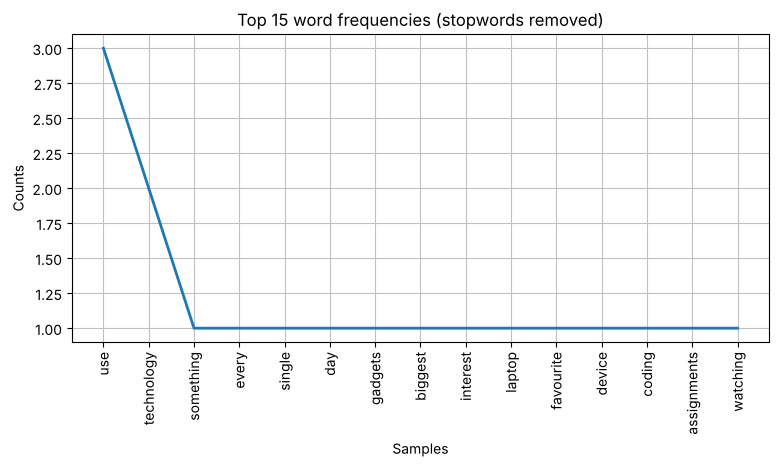

In [7]:
import matplotlib.pyplot as plt
from nltk.probability import FreqDist

fdist = FreqDist(filtered_words)
print(fdist.most_common(10))

plt.figure(figsize=(9, 4))
fdist.plot(15, title="Top 15 word frequencies (stopwords removed)")
plt.show()

## Q2. Regex extraction, stemming and lemmatization (same paragraph)

### 1. Extract alphabet-only words using `re.findall()`

In [8]:
alpha_words = re.findall(r'[a-zA-Z]+', paragraph.lower())
print(len(alpha_words), alpha_words)

101 ['technology', 'is', 'something', 'i', 'use', 'every', 'single', 'day', 'and', 'gadgets', 'are', 'my', 'biggest', 'interest', 'my', 'laptop', 'is', 'my', 'favourite', 'device', 'because', 'i', 'use', 'it', 'for', 'coding', 'assignments', 'and', 'watching', 'tutorials', 'i', 'always', 'follow', 'the', 'launch', 'of', 'new', 'smartphones', 'smartwatches', 'and', 'earbuds', 'with', 'a', 'lot', 'of', 'excitement', 'for', 'me', 'a', 'good', 'gadget', 'is', 'not', 'only', 'about', 'specs', 'it', 'is', 'about', 'the', 'design', 'battery', 'backup', 'and', 'how', 'easy', 'it', 'is', 'to', 'use', 'last', 'semester', 'my', 'friends', 'and', 'i', 'made', 'a', 'small', 'line', 'following', 'robot', 'in', 'the', 'college', 'lab', 'using', 'an', 'arduino', 'i', 'feel', 'technology', 'saves', 'time', 'solves', 'problems', 'and', 'makes', 'learning', 'more', 'fun']


### 2. Remove stopwords

In [9]:
q2_words = [w for w in alpha_words if w not in stop_words]
print(q2_words)

['technology', 'something', 'use', 'every', 'single', 'day', 'gadgets', 'biggest', 'interest', 'laptop', 'favourite', 'device', 'use', 'coding', 'assignments', 'watching', 'tutorials', 'always', 'follow', 'launch', 'new', 'smartphones', 'smartwatches', 'earbuds', 'lot', 'excitement', 'good', 'gadget', 'specs', 'design', 'battery', 'backup', 'easy', 'use', 'last', 'semester', 'friends', 'made', 'small', 'line', 'following', 'robot', 'college', 'lab', 'using', 'arduino', 'feel', 'technology', 'saves', 'time', 'solves', 'problems', 'makes', 'learning', 'fun']


### 3. Stemming with PorterStemmer

In [10]:
from nltk.stem import PorterStemmer
ps = PorterStemmer()
stemmed = [ps.stem(w) for w in q2_words]
print(stemmed)

['technolog', 'someth', 'use', 'everi', 'singl', 'day', 'gadget', 'biggest', 'interest', 'laptop', 'favourit', 'devic', 'use', 'code', 'assign', 'watch', 'tutori', 'alway', 'follow', 'launch', 'new', 'smartphon', 'smartwatch', 'earbud', 'lot', 'excit', 'good', 'gadget', 'spec', 'design', 'batteri', 'backup', 'easi', 'use', 'last', 'semest', 'friend', 'made', 'small', 'line', 'follow', 'robot', 'colleg', 'lab', 'use', 'arduino', 'feel', 'technolog', 'save', 'time', 'solv', 'problem', 'make', 'learn', 'fun']


### 4. Lemmatization with WordNetLemmatizer

In [11]:
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
lemmatized = [lemmatizer.lemmatize(w) for w in q2_words]              # default POS = noun
lemmatized_v = [lemmatizer.lemmatize(w, pos='v') for w in q2_words]   # treating words as verbs
print("Noun  :", lemmatized)
print("Verb  :", lemmatized_v)

Noun  : ['technology', 'something', 'use', 'every', 'single', 'day', 'gadget', 'biggest', 'interest', 'laptop', 'favourite', 'device', 'use', 'coding', 'assignment', 'watching', 'tutorial', 'always', 'follow', 'launch', 'new', 'smartphones', 'smartwatches', 'earbuds', 'lot', 'excitement', 'good', 'gadget', 'spec', 'design', 'battery', 'backup', 'easy', 'use', 'last', 'semester', 'friend', 'made', 'small', 'line', 'following', 'robot', 'college', 'lab', 'using', 'arduino', 'feel', 'technology', 'save', 'time', 'solves', 'problem', 'make', 'learning', 'fun']
Verb  : ['technology', 'something', 'use', 'every', 'single', 'day', 'gadgets', 'biggest', 'interest', 'laptop', 'favourite', 'device', 'use', 'cod', 'assignments', 'watch', 'tutorials', 'always', 'follow', 'launch', 'new', 'smartphones', 'smartwatches', 'earbuds', 'lot', 'excitement', 'good', 'gadget', 'specs', 'design', 'battery', 'backup', 'easy', 'use', 'last', 'semester', 'friends', 'make', 'small', 'line', 'follow', 'robot', 'c

### 5. Comparison

In [12]:
import pandas as pd
df = pd.DataFrame({'Original': q2_words, 'Stemmed': stemmed,
                   'Lemma (noun)': lemmatized, 'Lemma (verb)': lemmatized_v})
print(df.to_string(index=False))

print("\nWords where stem is not a real word:")
print(df[df['Original'] != df['Stemmed']][['Original', 'Stemmed']].head(10).to_string(index=False))

    Original    Stemmed Lemma (noun) Lemma (verb)
  technology  technolog   technology   technology
   something     someth    something    something
         use        use          use          use
       every      everi        every        every
      single      singl       single       single
         day        day          day          day
     gadgets     gadget       gadget      gadgets
     biggest    biggest      biggest      biggest
    interest   interest     interest     interest
      laptop     laptop       laptop       laptop
   favourite   favourit    favourite    favourite
      device      devic       device       device
         use        use          use          use
      coding       code       coding          cod
 assignments     assign   assignment  assignments
    watching      watch     watching        watch
   tutorials     tutori     tutorial    tutorials
      always      alway       always       always
      follow     follow       follow       follow


**Comparison**
- Stemming just cuts off word endings using fixed rules, so the output is often not a proper word. For example `technology` became `technolog`, `device` became `devic`, `battery` became `batteri` and `easy` became `easi`.
- Lemmatization uses the WordNet dictionary, so it always gives a real word (`friends` -> `friend`, `technology` stays `technology`). It also depends on the POS tag: with the default noun tag `following` stays `following`, but with the verb tag it becomes `follow`.
- Stemming is faster but less accurate. Lemmatization is slower but more accurate.

**When to use which**
- I would prefer **stemming** when speed matters and exact words do not, for example in a search engine or when classifying a large number of documents.
- I would prefer **lemmatization** when the meaning of the word matters, for example in sentiment analysis, chatbots or text generation.

## Q3. Bag of Words and TF-IDF

In [13]:
texts = [
    "The new smartphone has a bright display, a fast processor and a battery that lasts two days.",
    "Indian cricket team won the series after a brilliant century from the captain in the final match.",
    "The restaurant served delicious butter chicken with soft naan and the staff was very friendly."
]
for i, t in enumerate(texts, 1):
    print(f"Text {i}: {t}")

Text 1: The new smartphone has a bright display, a fast processor and a battery that lasts two days.
Text 2: Indian cricket team won the series after a brilliant century from the captain in the final match.
Text 3: The restaurant served delicious butter chicken with soft naan and the staff was very friendly.


### 1. CountVectorizer (Bag of Words)

In [14]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

cv = CountVectorizer(stop_words='english')
bow = cv.fit_transform(texts)

bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(),
                      index=['Text 1', 'Text 2', 'Text 3'])
print(bow_df)

        battery  bright  brilliant  butter  captain  century  chicken  \
Text 1        1       1          0       0        0        0        0   
Text 2        0       0          1       0        1        1        0   
Text 3        0       0          0       1        0        0        1   

        cricket  days  delicious  ...  new  processor  restaurant  series  \
Text 1        0     1          0  ...    1          1           0       0   
Text 2        1     0          0  ...    0          0           0       1   
Text 3        0     0          1  ...    0          0           1       0   

        served  smartphone  soft  staff  team  won  
Text 1       0           1     0      0     0    0  
Text 2       0           0     0      0     1    1  
Text 3       1           0     1      1     0    0  

[3 rows x 28 columns]


### 2. TfidfVectorizer

In [15]:
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(texts)

tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf.get_feature_names_out(),
                        index=['Text 1', 'Text 2', 'Text 3'])
print(tfidf_df.round(3))

        battery  bright  brilliant  butter  captain  century  chicken  \
Text 1    0.333   0.333      0.000   0.000    0.000    0.000    0.000   
Text 2    0.000   0.000      0.316   0.000    0.316    0.316    0.000   
Text 3    0.000   0.000      0.000   0.333    0.000    0.000    0.333   

        cricket   days  delicious  ...    new  processor  restaurant  series  \
Text 1    0.000  0.333      0.000  ...  0.333      0.333       0.000   0.000   
Text 2    0.316  0.000      0.000  ...  0.000      0.000       0.000   0.316   
Text 3    0.000  0.000      0.333  ...  0.000      0.000       0.333   0.000   

        served  smartphone   soft  staff   team    won  
Text 1   0.000       0.333  0.000  0.000  0.000  0.000  
Text 2   0.000       0.000  0.000  0.000  0.316  0.316  
Text 3   0.333       0.000  0.333  0.333  0.000  0.000  

[3 rows x 28 columns]


### 3. Top 3 keywords of each text

In [16]:
feature_names = tfidf.get_feature_names_out()
for i in range(len(texts)):
    row = tfidf_matrix[i].toarray().flatten()
    top3 = row.argsort()[::-1][:3]
    print(f"Text {i+1} top 3 keywords:")
    for idx in top3:
        print(f"   {feature_names[idx]:<12} {row[idx]:.3f}")

Text 1 top 3 keywords:
   processor    0.333
   new          0.333
   smartphone   0.333
Text 2 top 3 keywords:
   won          0.316
   team         0.316
   match        0.316
Text 3 top 3 keywords:
   soft         0.333
   staff        0.333
   restaurant   0.333


**Interpretation**
- In Bag of Words each word only gets a count, so a common word and an important word look the same.
- TF-IDF gives a higher score to words that are special to one text and a lower score to words that appear in many texts.
- Here the three texts are about different topics (a phone, a cricket match and a restaurant), so most words appear in only one text and get similar scores. Words with the same score are shown in no particular order.
- Top keywords: Text 1 = *processor, new, smartphone*, Text 2 = *won, team, match*, Text 3 = *soft, staff, restaurant*. These words clearly point to the topic of each text (technology, sports and food).

## Q4. Jaccard and Cosine similarity

In [17]:
tech1 = ("Machine learning lets computers learn from data instead of being programmed with fixed rules. "
         "It is widely used in recommendation systems, healthcare and fraud detection. "
         "Models like neural networks become more accurate when they are trained on larger datasets. "
         "Machine learning also helps to automate decisions and predict future trends.")

tech2 = ("Cybersecurity is the practice of protecting computers, networks and data from digital attacks. "
         "It is widely used in banking, healthcare and government systems to stop fraud and data theft. "
         "Tools like firewalls, encryption and antivirus software help to detect and block threats. "
         "Cybersecurity also helps organisations keep sensitive data safe and maintain user trust.")

### 1. Preprocess and tokenize

In [18]:
def preprocess(text):
    text = re.sub(r'[^\w\s]', '', text.lower())
    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in stop_words]
    return tokens

tokens1 = preprocess(tech1)
tokens2 = preprocess(tech2)
print("ML tokens           :", tokens1)
print("Cybersecurity tokens:", tokens2)

ML tokens           : ['machine', 'learning', 'lets', 'computers', 'learn', 'data', 'instead', 'programmed', 'fixed', 'rules', 'widely', 'used', 'recommendation', 'systems', 'healthcare', 'fraud', 'detection', 'models', 'like', 'neural', 'networks', 'become', 'accurate', 'trained', 'larger', 'datasets', 'machine', 'learning', 'also', 'helps', 'automate', 'decisions', 'predict', 'future', 'trends']
Cybersecurity tokens: ['cybersecurity', 'practice', 'protecting', 'computers', 'networks', 'data', 'digital', 'attacks', 'widely', 'used', 'banking', 'healthcare', 'government', 'systems', 'stop', 'fraud', 'data', 'theft', 'tools', 'like', 'firewalls', 'encryption', 'antivirus', 'software', 'help', 'detect', 'block', 'threats', 'cybersecurity', 'also', 'helps', 'organisations', 'keep', 'sensitive', 'data', 'safe', 'maintain', 'user', 'trust']


### 2a. Jaccard similarity (using sets)

In [19]:
set1, set2 = set(tokens1), set(tokens2)
intersection = set1 & set2
union = set1 | set2

jaccard = len(intersection) / len(union)
print("Common words:", intersection)
print("Union size  :", len(union))
print("Jaccard similarity:", round(jaccard, 4))

Common words: {'systems', 'also', 'helps', 'widely', 'used', 'fraud', 'healthcare', 'data', 'like', 'networks', 'computers'}
Union size  : 58
Jaccard similarity: 0.1897


### 2b. Cosine similarity (TfidfVectorizer + cosine_similarity)

In [20]:
from sklearn.metrics.pairwise import cosine_similarity

clean1, clean2 = ' '.join(tokens1), ' '.join(tokens2)
vec = TfidfVectorizer()
tfidf_vecs = vec.fit_transform([clean1, clean2])

cos_sim = cosine_similarity(tfidf_vecs[0], tfidf_vecs[1])[0][0]
print("Cosine similarity:", round(cos_sim, 4))

Cosine similarity: 0.1852


### 2c. Analysis

In [21]:
print(f"Jaccard : {jaccard:.4f}")
print(f"Cosine  : {cos_sim:.4f}")

Jaccard : 0.1897
Cosine  : 0.1852


**Analysis**
- Jaccard similarity = 0.1897 and cosine similarity = 0.1852. Both are low, which is correct because Machine Learning and Cybersecurity are different topics. They share only words like *used, data, healthcare, fraud, systems*.
- Jaccard only checks which words are present in both texts. It does not care how many times a word is used or how important it is.
- Cosine similarity with TF-IDF also considers word frequency and gives less weight to common words, and it is not affected much by the length of the text.
- In my case I feel **cosine similarity with TF-IDF gives better insight**, because it shows similarity based on important words and not just on common words. Jaccard is simpler and good for a quick overlap check on short texts.

## Q5. Sentiment analysis (TextBlob) and word cloud

In [22]:
from textblob import TextBlob

reviews = [
    "I bought this laptop last month and I am amazed. The display is excellent and the battery easily lasts a full day.",
    "Worst laptop ever. It gets very hot within ten minutes and the customer support was rude.",
    "The delivery was on time and the box contains the laptop as described.",
    "I love this laptop, it is fast, light and totally worth the money.",
    "Very disappointing quality, the keyboard stopped working after just two days.",
    "Great performance and a beautiful screen, I am really happy with this purchase.",
    "The package arrived yesterday. It contains a laptop, a charger and a user manual.",
    "Excellent build quality and smooth performance, the best laptop in this price range."
]

### 1 & 2. Polarity, subjectivity and classification

In [23]:
results = []
for r in reviews:
    blob = TextBlob(r)
    pol = blob.sentiment.polarity
    sub = blob.sentiment.subjectivity
    if pol > 0.1:
        label = "Positive"
    elif pol < -0.1:
        label = "Negative"
    else:
        label = "Neutral"
    results.append((r, round(pol, 3), round(sub, 3), label))

import pandas as pd
sent_df = pd.DataFrame(results, columns=['Review', 'Polarity', 'Subjectivity', 'Sentiment'])
pd.set_option('display.max_colwidth', 70)
print(sent_df)
print()
print(sent_df['Sentiment'].value_counts())

                                                                  Review  \
0  I bought this laptop last month and I am amazed. The display is ex...   
1  Worst laptop ever. It gets very hot within ten minutes and the cus...   
2  The delivery was on time and the box contains the laptop as descri...   
3     I love this laptop, it is fast, light and totally worth the money.   
4  Very disappointing quality, the keyboard stopped working after jus...   
5  Great performance and a beautiful screen, I am really happy with t...   
6  The package arrived yesterday. It contains a laptop, a charger and...   
7  Excellent build quality and smooth performance, the best laptop in...   

   Polarity  Subjectivity Sentiment  
0     0.446         0.613  Positive  
1    -0.244         0.650  Negative  
2     0.000         0.000   Neutral  
3     0.350         0.500  Positive  
4    -0.780         0.910  Negative  
5     0.817         0.917  Positive  
6     0.000         0.000   Neutral  
7     0.800

### 3. Word cloud of positive reviews

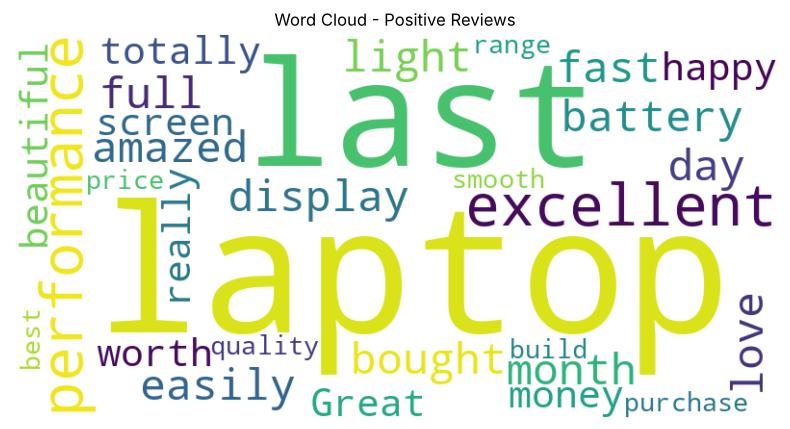

In [24]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

positive_text = ' '.join(sent_df[sent_df['Sentiment'] == 'Positive']['Review'])
wc = WordCloud(width=800, height=400, background_color='white',
               stopwords=set(stopwords.words('english'))).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud - Positive Reviews")
plt.show()

## Q6. Text generation using LSTM

In [25]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

training_text = (
    "technology is a part of our daily life. every new gadget makes work easier and faster. "
    "a laptop helps students to study and to code. "
    "the smartphone keeps people connected with friends and family. "
    "good software and strong hardware work together in every device. "
    "engineers test each product again and again before launch. "
    "a long battery life and a clear display make a device more useful. "
    "students use online tools to learn new skills at home. "
    "learning new technology teaches us patience and curiosity. "
    "the future of technology will bring smarter and faster devices for everyone."
)
print("Number of words in training text:", len(training_text.split()))

Number of words in training text: 96


### 1. Tokenize using Keras `Tokenizer`

In [26]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1
print("Vocabulary size:", total_words)
print(list(tokenizer.word_index.items())[:10])

Vocabulary size: 71
[('and', 1), ('a', 2), ('technology', 3), ('new', 4), ('to', 5), ('of', 6), ('life', 7), ('every', 8), ('work', 9), ('faster', 10)]


### 2. Create input sequences (n-gram sequences) and build the model

In [27]:
input_sequences = []
for line in training_text.split('. '):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i + 1])       # 1st 2 words, 1st 3 words, ...

max_len = max(len(seq) for seq in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_len, padding='pre')

X = input_sequences[:, :-1]      # all words except last = input
y = input_sequences[:, -1]       # last word = label
y = to_categorical(y, num_classes=total_words)
print("Total sequences:", len(input_sequences), " X shape:", X.shape, " y shape:", y.shape)

Total sequences: 86  X shape: (86, 12)  y shape: (86, 71)


In [28]:
model = Sequential([
    Embedding(total_words, 50),
    LSTM(100),
    Dense(total_words, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.build(input_shape=(None, max_len - 1))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 12, 50)         │         3,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100)            │        60,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 71)             │         7,171 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,121 (277.82 KB)

 Trainable params: 71,121 (277.82 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Train the model

Final loss    : 0.1995
Final accuracy: 0.9767


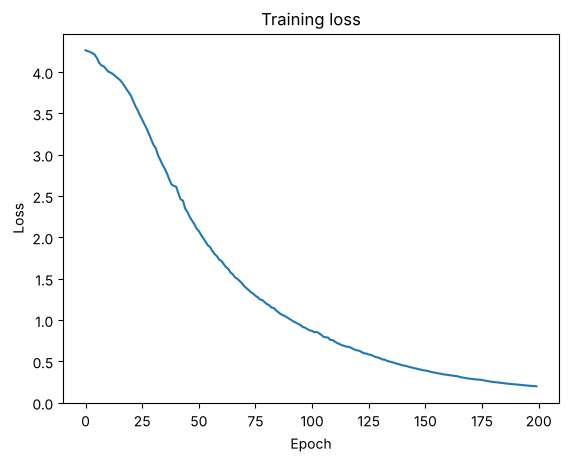

In [29]:
history = model.fit(X, y, epochs=200, verbose=0)
print("Final loss    :", round(history.history['loss'][-1], 4))
print("Final accuracy:", round(history.history['accuracy'][-1], 4))

plt.plot(history.history['loss'])
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Training loss')
plt.show()

### 4. Generate new text from a seed word

In [30]:
def generate_text(seed_text, next_words=8):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_len - 1, padding='pre')
        predicted = np.argmax(model.predict(token_list, verbose=0), axis=-1)[0]
        for word, index in tokenizer.word_index.items():
            if index == predicted:
                seed_text += ' ' + word
                break
    return seed_text

for seed in ["technology", "a laptop", "every new"]:
    print(generate_text(seed))

technology is a part of our daily life life


a laptop helps students to study and to code code


every new gadget makes work easier and faster faster for


## Conclusion
In this assignment I practised text preprocessing (cleaning, tokenizing, stopword removal), stemming and lemmatization, and converted text
into numbers using Bag of Words and TF-IDF. I then compared two texts using Jaccard and cosine similarity, did sentiment analysis of laptop
reviews using TextBlob, and generated text using a simple LSTM model. The training data for the LSTM is very small (about 100 words), so the
generated text repeats words and is not perfect. A bigger dataset would give better results.